# REPD — Pipeline timeline (applications since 2010)

Follows every application **submitted on or after 1 Jan 2010** as it moves through the planning pipeline.
Each column is a quarter-end snapshot (the last is the latest REPD update), showing the stage every project was at on that date.
New applications fan in from the top, and ribbons show projects changing stage between snapshots.

**How stage is worked out:** each project follows the path implied by its current `Development Status (short)`, e.g. Operational = Submitted → Awaiting construction → Under construction → Operational. Its stage on a date is the last stage on that path whose date has passed.

**Excluded:** Revised and No Application Required (they aren't stages in this pipeline).

In [1]:
from pathlib import Path

import pandas as pd

from repd.processor import REPDProcessor
from repd.visualise import plot_alluvial

REPD_CSV = Path("../data/REPD_Publication_Q2_2026.csv")
START = pd.Timestamp("2010-01-01")

In [2]:
processor = REPDProcessor(REPD_CSV, encoding="latin-1")
df = processor.convert_datetime(processor.load())
# End at the last full quarter before the latest REPD update, so no column is a partial stub.
end = df["Record Last Updated (dd/mm/yyyy)"].max().to_period("Q").start_time - pd.Timedelta(days=1)

## 1. Load and build the cohort

In [3]:
# End at the last full quarter before the latest REPD update, so no column is a partial stub.
end = df["Record Last Updated (dd/mm/yyyy)"].max().to_period("Q").start_time - pd.Timedelta(days=1)

# Date each stage was reached. Appeal outcomes count as the same drop-out.
STAGE_DATE = {
    "Submitted":          df["Planning Application Submitted"],
    "Awaiting construction":            df["Planning Permission Granted"],
    "Under construction": df["Under Construction"],
    "Operational":        df["Operational"],
    "Refused":            df["Planning Permission Refused"].fillna(df["Appeal Refused"]),
    "Withdrawn":          df["Planning Application Withdrawn"].fillna(df["Appeal Withdrawn"]),
    "Expired / abandoned": df["Planning Permission Expired"],
}

PATHS = {
    "Application Submitted":       ["Submitted"],
    "Application Refused":         ["Submitted", "Refused"],
    "Appeal Refused":              ["Submitted", "Refused"],
    "Appeal Lodged":               ["Submitted", "Refused"],
    "Application Withdrawn":       ["Submitted", "Withdrawn"],
    "Appeal Withdrawn":            ["Submitted", "Withdrawn"],
    "Awaiting Construction":       ["Submitted", "Awaiting construction"],
    "Planning Permission Expired": ["Submitted", "Awaiting construction", "Expired / abandoned"],
    "Abandoned":                   ["Submitted", "Expired / abandoned"],
    "Under Construction":          ["Submitted", "Awaiting construction", "Under construction"],
    "Operational":                 ["Submitted", "Awaiting construction", "Under construction", "Operational"],
}

status = df["Development Status (short)"]
cohort = df[df["Planning Application Submitted"].between(START, end) & status.isin(PATHS)]
print(f"Cohort: {len(cohort):,} applications submitted {START:%d %b %Y} → {end:%d %b %Y}")
cohort["Development Status (short)"].value_counts()

Cohort: 12,147 applications submitted 01 Jan 2010 → 30 Jun 2026


Development Status (short)
Awaiting Construction          5942
Operational                    2060
Application Submitted          1534
Application Refused             760
Application Withdrawn           520
Under Construction              435
Planning Permission Expired     304
Abandoned                       288
Appeal Refused                  257
Appeal Withdrawn                 41
Appeal Lodged                     6
Name: count, dtype: int64

## 2. Stage of every project at each quarter-end

In [4]:
snapshots = list(pd.date_range(START, end, freq="QE"))

# One row per (project, stage on its path) with the date reached.
steps = cohort["Development Status (short)"].map(PATHS).explode().rename("stage").to_frame()
steps["date"] = [STAGE_DATE[s].at[i] for i, s in steps["stage"].items()]
# shortcut: a missing stage date (<10 projects) falls back to Record Last Updated; fine at this scale, revisit if gaps grow.
steps["date"] = steps["date"].fillna(cohort["Record Last Updated (dd/mm/yyyy)"].reindex(steps.index))
# Data-entry errors can put a later stage before an earlier one; keep dates monotonic along the path.
steps["date"] = steps.groupby(level=0)["date"].cummax()


def stage_on(d: pd.Timestamp) -> pd.Series:
    """Last stage each project had reached by date d (NaN if not yet submitted)."""
    reached = steps[steps["date"] <= d]
    return reached.groupby(level=0)["stage"].last().reindex(cohort.index)


states = pd.DataFrame({d: stage_on(d) for d in snapshots})

# Self-checks: the last snapshot matches each project's current status (bar decisions logged after it), and the cohort only grows.
final = cohort["Development Status (short)"].map(lambda s: PATHS[s][-1])
assert (states[end] == final).mean() > 0.99, "final snapshot should match current status"
assert states.notna().sum().is_monotonic_increasing

states.apply(pd.Series.value_counts).fillna(0).astype(int).rename(columns=lambda d: f"{d:%b %Y}")

,Mar 2010,Jun 2010,Sep 2010,Dec 2010,Mar 2011,Jun 2011,Sep 2011,Dec 2011,Mar 2012,Jun 2012,...,Mar 2024,Jun 2024,Sep 2024,Dec 2024,Mar 2025,Jun 2025,Sep 2025,Dec 2025,Mar 2026,Jun 2026
Awaiting construction,1,6,17,35,72,140,148,165,183,195,...,3162,3475,3740,4022,4356,4700,5133,5432,5733,5938
Expired / abandoned,0,0,0,0,3,3,3,5,5,7,...,572,575,576,576,577,578,580,581,584,587
Operational,0,0,0,0,0,1,20,23,25,34,...,1936,1943,1957,1969,1981,1991,2005,2013,2035,2058
Refused,0,2,2,8,17,26,31,41,51,61,...,750,771,784,806,827,869,899,955,999,1023
Submitted,44,80,115,170,243,234,241,263,320,329,...,1312,1330,1423,1553,1628,1658,1672,1638,1578,1546
Under construction,0,0,0,0,1,5,9,11,16,29,...,328,339,341,343,368,392,402,417,427,434
Withdrawn,0,1,1,1,1,6,11,15,18,26,...,421,438,455,473,489,502,518,535,550,561


## 3. Timeline

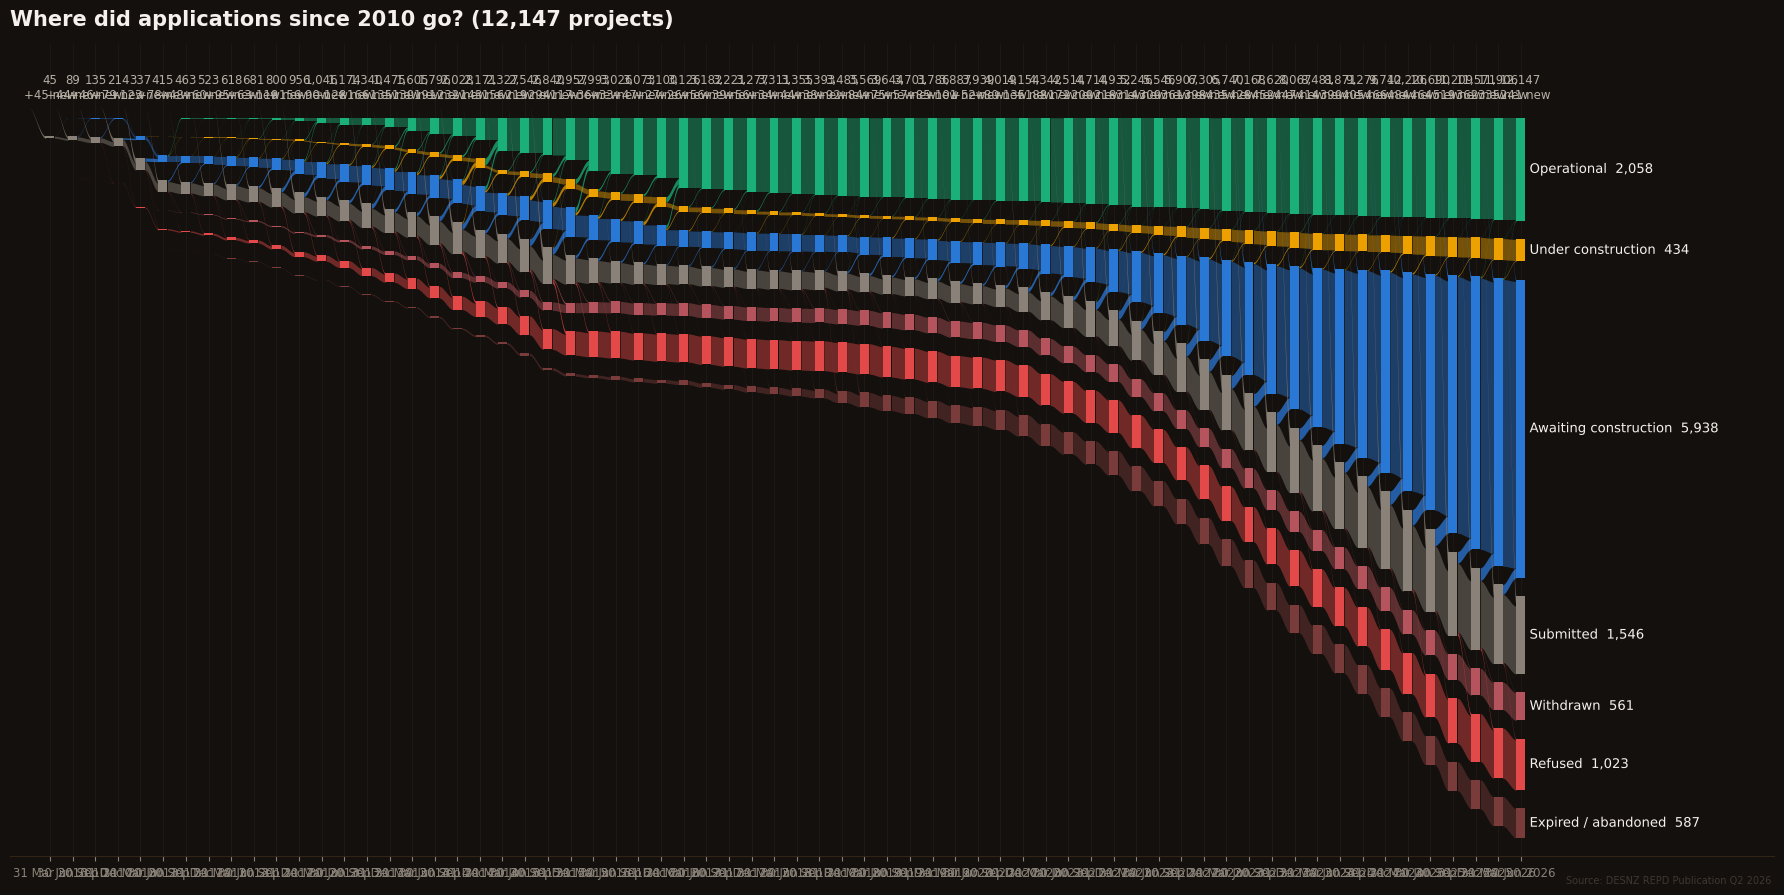

In [5]:
ORDER = ["Operational", "Under construction", "Awaiting construction", "Submitted",
         "Withdrawn", "Refused", "Expired / abandoned"]
COLORS = {
    "Submitted": "#8a8278", "Awaiting construction": "#2a78d6", "Under construction": "#eda100",
    "Operational": "#1baf7a", "Refused": "#e34948", "Withdrawn": "#b5545c",
    "Expired / abandoned": "#7a3b3b",
}

fig = plot_alluvial(
    states,
    order=ORDER,
    colors=COLORS,
    title=f"Where did applications since {START:%Y} go? ({len(cohort):,} projects)",
    origin=START,
    credit=f"Source: DESNZ {REPD_CSV.stem.replace('_', ' ')}",
)
fig.savefig("pipeline_timeline.png", dpi=150, bbox_inches="tight")

**Reading it:** the grey band is applications still waiting for a decision, and blue is awaiting construction (granted but not yet started).
Recent quarters can look better or worse than they are, because REPD records new decisions with a lag.